# 01 - Decision Tree và Random Forest trên Credit Card

Mục tiêu: dự đoán khách hàng có default payment tháng kế tiếp bằng Decision Tree và Random Forest. Các siêu tham số được chọn bằng cross-validation trên tập train; tập test chỉ dùng cho đánh giá cuối cùng.

## 1. Load data và EDA 

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 24
NOTEBOOK_NAME = "01_credit_card_dt_rf"
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = BASE_DIR / "data"
FIGURES_DIR = BASE_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_DIR / "credit_card.csv")
print(f"Shape ban đầu: {df.shape}")
display(df.head())
display(df.info())
print("Missing theo cột:")
display(df.isna().sum().to_frame("missing").T)
target_col = "default payment next month"
display(df[target_col].value_counts(normalize=True).rename("proportion").to_frame())


Shape ban đầu: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

None

Missing theo cột:


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
missing,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,proportion
default payment next month,
0,0.7788
1,0.2212


## 2. Làm sạch và chia dữ liệu

Đổi `PAY_0` thành `PAY_1`, loại các dòng có `EDUCATION` thuộc `{0, 5, 6}` hoặc `MARRIAGE = 0`, sau đó bỏ các cột không dùng theo đề.

In [2]:
df = df.rename(columns={"PAY_0": "PAY_1"})
rows_before = len(df)
df = df.loc[~df["EDUCATION"].isin([0, 5, 6]) & (df["MARRIAGE"] != 0)].copy()
print(f"Số dòng trước khi lọc: {rows_before}")
print(f"Số dòng sau khi lọc: {len(df)}")

drop_columns = ["ID", "SEX", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
df = df.drop(columns=drop_columns)
feature_columns = [column for column in df.columns if column != target_col]
X = df[feature_columns]
y = df[target_col].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Số feature: {X.shape[1]}")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")


Số dòng trước khi lọc: 30000
Số dòng sau khi lọc: 29601
Số feature: 17
Train: (23680, 17), Test: (5921, 17)


## 3. Decision Tree với `max_depth=2`

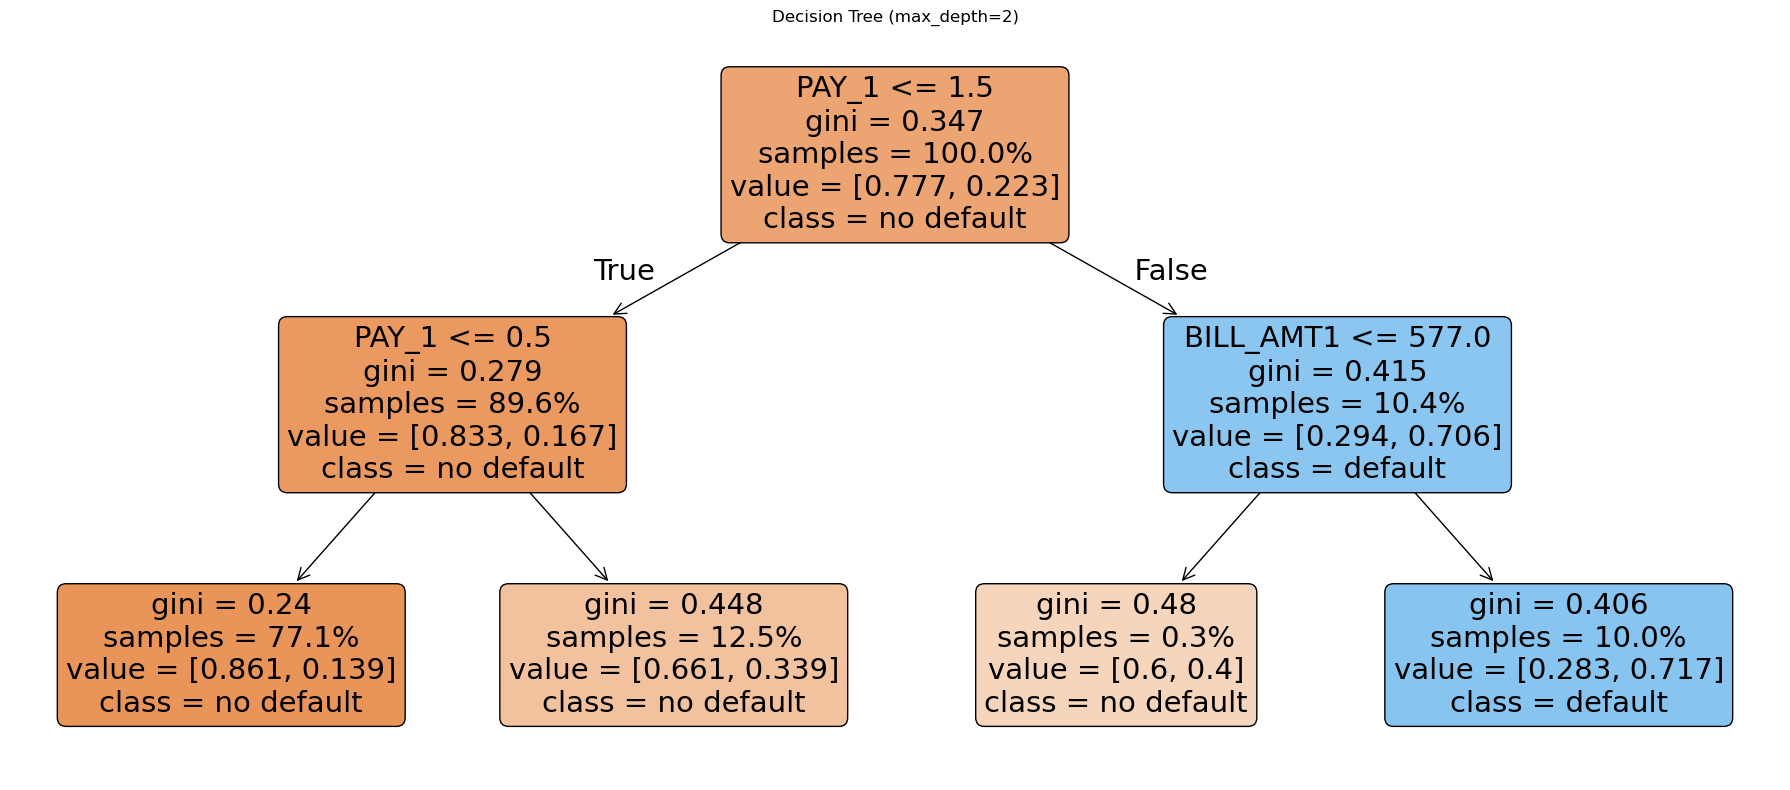

In [3]:
tree_depth2 = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)
tree_depth2.fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(
    tree_depth2,
    feature_names=feature_columns,
    class_names=["no default", "default"],
    filled=True,
    rounded=True,
    proportion=True,
    ax=ax,
)
ax.set_title("Decision Tree (max_depth=2)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_tree_depth2.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Tuning Decision Tree bằng ROC AUC

,max_depth,train_mean,train_std,test_mean,test_std
0,1,0.644416,0.002649,0.644416,0.007947
1,2,0.700516,0.002080,0.700464,0.006341
2,4,0.751737,0.002253,0.741082,0.005977
3,6,0.776884,0.001882,0.746218,0.007837
4,8,0.805846,0.001652,0.737551,0.009413
5,10,0.843651,0.003156,0.713447,0.006351
6,12,0.888739,0.003753,0.678951,0.008710


Best params: {'max_depth': 6}
Best CV ROC AUC: 0.7462


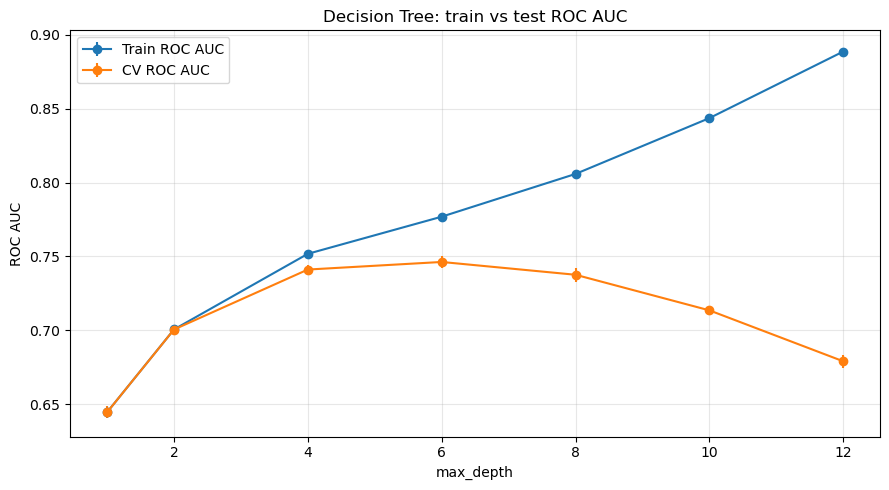

In [4]:
tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid={"max_depth": [1, 2, 4, 6, 8, 10, 12]},
    scoring="roc_auc",
    cv=4,
    return_train_score=True,
    n_jobs=-1,
    error_score=np.nan,
)
tree_grid.fit(X_train, y_train)
tree_cv = pd.DataFrame(tree_grid.cv_results_)
tree_summary = tree_cv[["param_max_depth", "mean_train_score", "std_train_score", "mean_test_score", "std_test_score"]].copy()
tree_summary.columns = ["max_depth", "train_mean", "train_std", "test_mean", "test_std"]
display(tree_summary)
print("Best params:", tree_grid.best_params_)
print(f"Best CV ROC AUC: {tree_grid.best_score_:.4f}")

depths = tree_summary["max_depth"].astype(int)
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(depths, tree_summary["train_mean"], yerr=tree_summary["train_std"] / 2, marker="o", label="Train ROC AUC")
ax.errorbar(depths, tree_summary["test_mean"], yerr=tree_summary["test_std"] / 2, marker="o", label="CV ROC AUC")
ax.set(xlabel="max_depth", ylabel="ROC AUC", title="Decision Tree: train vs test ROC AUC")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_tree_depth_tuning.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Tuning Random Forest theo số cây

,n_estimators,mean_fit_time,mean_test_score,std_test_score
0,10,1.202938,0.727745,0.007450
1,20,1.852406,0.742455,0.007119
2,30,3.108142,0.749103,0.006202
3,40,4.040785,0.753819,0.005911
4,50,5.140786,0.756114,0.005437
5,60,6.421808,0.757228,0.005428
6,70,8.661908,0.758351,0.005709
7,80,23.046204,0.759412,0.005634
8,90,18.033449,0.760376,0.005701
9,100,18.872617,0.760476,0.005358


Best params: {'n_estimators': 100}
Best CV ROC AUC: 0.7605


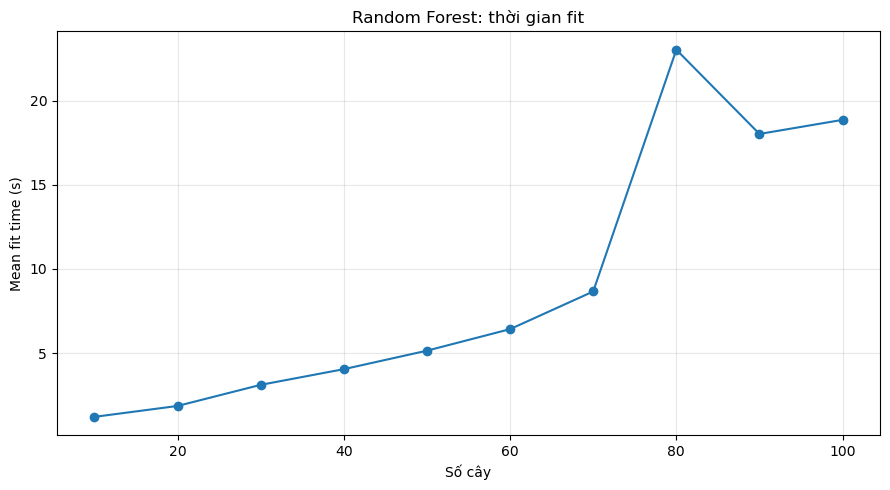

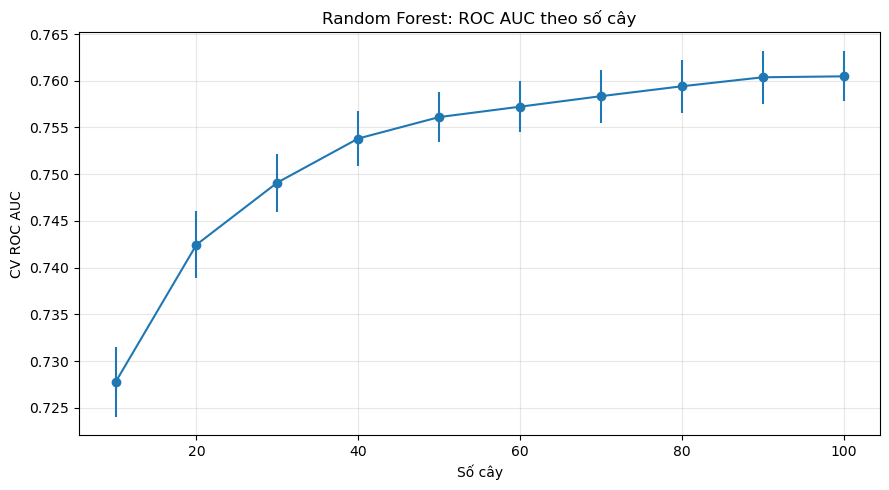

In [5]:
forest_grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={"n_estimators": list(range(10, 101, 10))},
    scoring="roc_auc",
    cv=4,
    return_train_score=True,
    n_jobs=-1,
    error_score=np.nan,
)
forest_grid.fit(X_train, y_train)
forest_cv = pd.DataFrame(forest_grid.cv_results_)
forest_summary = forest_cv[["param_n_estimators", "mean_fit_time", "mean_test_score", "std_test_score"]].copy()
forest_summary.columns = ["n_estimators", "mean_fit_time", "mean_test_score", "std_test_score"]
forest_summary["n_estimators"] = forest_summary["n_estimators"].astype(int)
display(forest_summary)
print("Best params:", forest_grid.best_params_)
print(f"Best CV ROC AUC: {forest_grid.best_score_:.4f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(forest_summary["n_estimators"], forest_summary["mean_fit_time"], marker="o")
ax.set(xlabel="Số cây", ylabel="Mean fit time (s)", title="Random Forest: thời gian fit")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_rf_fit_time.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(
    forest_summary["n_estimators"],
    forest_summary["mean_test_score"],
    yerr=forest_summary["std_test_score"] / 2,
    marker="o",
)
ax.set(xlabel="Số cây", ylabel="CV ROC AUC", title="Random Forest: ROC AUC theo số cây")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_rf_roc_auc.png", dpi=150, bbox_inches="tight")
plt.show()


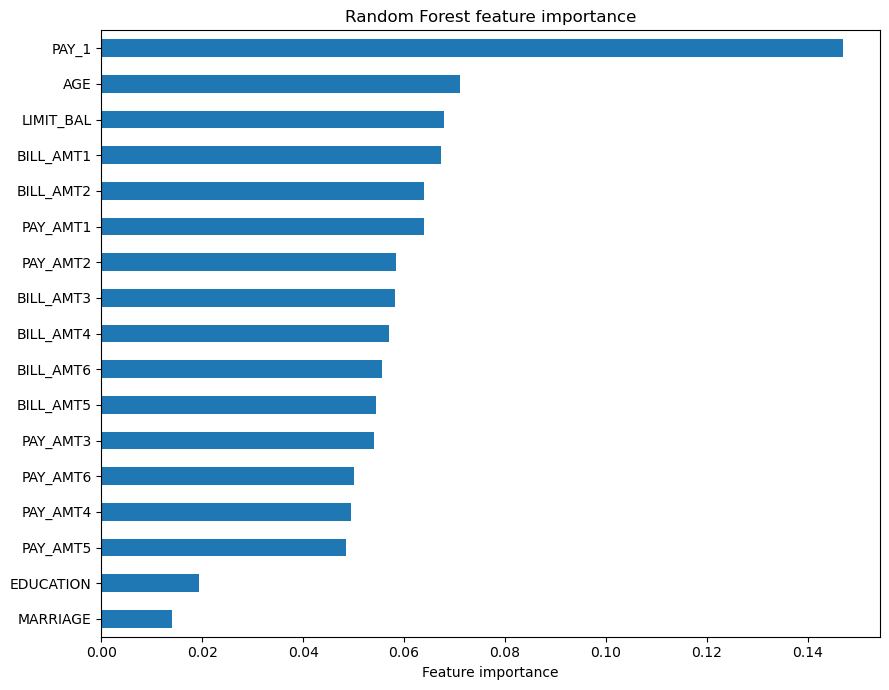

In [6]:
best_forest = forest_grid.best_estimator_
importance = pd.Series(best_forest.feature_importances_, index=feature_columns).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
importance.plot.barh(ax=ax)
ax.set(xlabel="Feature importance", title="Random Forest feature importance")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_rf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Đánh giá và nhận xét

Accuracy có thể cao do lớp default mất cân bằng, vì vậy recall, F1 và ROC AUC của lớp 1 được xem cùng với precision. So sánh điểm train và test giúp nhận diện overfitting.


DecisionTree
              precision    recall  f1-score   support

  no default       0.84      0.95      0.89      4600
     default       0.66      0.35      0.46      1321

    accuracy                           0.82      5921
   macro avg       0.75      0.65      0.67      5921
weighted avg       0.80      0.82      0.79      5921



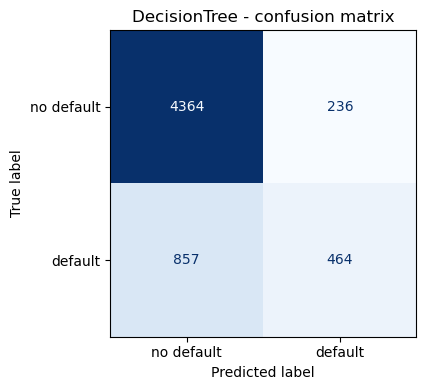


RandomForest
              precision    recall  f1-score   support

  no default       0.84      0.94      0.89      4600
     default       0.66      0.37      0.47      1321

    accuracy                           0.82      5921
   macro avg       0.75      0.66      0.68      5921
weighted avg       0.80      0.82      0.80      5921



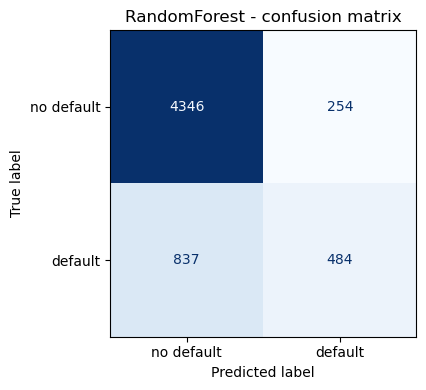

,notebook,dataset,model,accuracy,precision,recall,f1,roc_auc
0,01_credit_card_dt_rf,credit_card,DecisionTree,0.8154,0.6629,0.3512,0.4592,0.7506
1,01_credit_card_dt_rf,credit_card,RandomForest,0.8157,0.6558,0.3664,0.4701,0.7596


Nhận xét: mô hình tốt nhất theo ROC AUC trên test là RandomForest. Nếu train ROC AUC cao hơn CV/test đáng kể, đó là dấu hiệu overfitting; ngược lại điểm thấp ở cả hai phía có thể là underfitting.


In [7]:
models = {
    "DecisionTree": tree_grid.best_estimator_,
    "RandomForest": best_forest,
}
results = []
for model_name, model in models.items():
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]
    metrics = {
        "notebook": NOTEBOOK_NAME,
        "dataset": "credit_card",
        "model": model_name,
        "best_params": str(model.get_params() if model_name == "DecisionTree" else forest_grid.best_params_),
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_score),
    }
    results.append(metrics)
    print(f"\n{model_name}")
    print(classification_report(y_test, y_pred, target_names=["no default", "default"], zero_division=0))
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["no default", "default"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{model_name} - confusion matrix")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"01_{model_name.lower()}_confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()

results_df = pd.DataFrame(results)
display(results_df.drop(columns=["best_params"]).style.format({column: "{:.4f}" for column in ["accuracy", "precision", "recall", "f1", "roc_auc"]}))
best_model_name = results_df.loc[results_df["roc_auc"].idxmax(), "model"]
print(f"Nhận xét: mô hình tốt nhất theo ROC AUC trên test là {best_model_name}. Nếu train ROC AUC cao hơn CV/test đáng kể, đó là dấu hiệu overfitting; ngược lại điểm thấp ở cả hai phía có thể là underfitting.")


## 7. Bảng kết quả tóm tắt

Mỗi lần chạy sẽ thay các dòng của notebook này để file tổng hợp không bị trùng khi Restart & Run All.

In [8]:
summary_path = FIGURES_DIR / "results_summary.csv"
summary_columns = ["notebook", "dataset", "model", "best_params", "accuracy", "precision", "recall", "f1", "roc_auc"]
if summary_path.exists():
    previous = pd.read_csv(summary_path)
    previous = previous.loc[previous["notebook"] != NOTEBOOK_NAME]
    summary = pd.concat([previous, results_df[summary_columns]], ignore_index=True)
else:
    summary = results_df[summary_columns].copy()
summary.to_csv(summary_path, index=False)
display(summary)
print(f"Đã ghi {len(results_df)} dòng của {NOTEBOOK_NAME} vào {summary_path}")


,notebook,dataset,model,best_params,accuracy,precision,recall,f1,roc_auc
0,01_credit_card_dt_rf,credit_card,DecisionTree,"{'ccp_alpha': 0.0, 'class_weight': None, 'crit...",0.815403,0.662857,0.351249,0.459179,0.750627
1,01_credit_card_dt_rf,credit_card,RandomForest,{'n_estimators': 100},0.815741,0.655827,0.366389,0.470131,0.759643


Đã ghi 2 dòng của 01_credit_card_dt_rf vào D:\ML_Lab_Group_2026\Lab05_ModelTraining\Lab05\figures\results_summary.csv
